In [1]:
#Building a Crowd Counting Model 
#Dataset used: Shanghai Tech Dataset Part B

In [27]:
#Step 1: Data Loading
import os
import numpy as np
from scipy.io import loadmat
from PIL import Image

def load_data(data_dir):
    image_dir = os.path.join(data_dir, "images")
    gt_dir = os.path.join(data_dir, "ground-truth")
    image_files = os.listdir(image_dir)
    
    data = []
    for image_file in image_files:
        image_path = os.path.join(image_dir, image_file)
        gt_path = os.path.join(gt_dir, "GT_" + os.path.splitext(image_file)[0] + ".mat")
        image = np.array(Image.open(image_path).convert("RGB"))  # Load image
        gt_data = loadmat(gt_path)  # Load ground truth MAT file
        crowd_annotations = gt_data["image_info"][0][0][0][0][0]  # Extract crowd annotations
        crowd_count = len(crowd_annotations)  # Count the number of annotations to get crowd count
        data.append({"image": image, "crowd_count": crowd_count})
    
    return data

# Paths to train and test data directories
train_data_dir = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\train_data"
test_data_dir = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\test_data"

# Load train and test data
train_data = load_data(train_data_dir)
test_data = load_data(test_data_dir)

# Sample usage of loaded data
print("Number of train images:", len(train_data))
print("Number of test images:", len(test_data))
print("Example image shape:", train_data[0]["image"].shape)
print("Example crowd count:", train_data[0]["crowd_count"])


Number of train images: 400
Number of test images: 316
Example image shape: (768, 1024, 3)
Example crowd count: 233


In [56]:
#Step 2: Data Preprocessing 
import os
import cv2
import numpy as np
from scipy.io import loadmat
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.utils import normalize

# Define function for loading data
def load_data(data_dir):
    image_dir = os.path.join(data_dir, "images")
    gt_dir = os.path.join(data_dir, "ground-truth")
    image_files = os.listdir(image_dir)
    
    data = []
    for image_file in image_files:
        image_path = os.path.join(image_dir, image_file)
        gt_path = os.path.join(gt_dir, "GT_" + os.path.splitext(image_file)[0] + ".mat")
        
        # Check if image file exists and load image
        if os.path.isfile(image_path):
            image = np.array(Image.open(image_path).convert("RGB"))  # Load image
        else:
            print(f"Image file not found: {image_path}")
            continue
        
        # Check if ground truth file exists and load annotations
        if os.path.isfile(gt_path):
            gt_data = loadmat(gt_path)  # Load ground truth MAT file
            crowd_annotations = gt_data["image_info"][0][0][0][0][0]  # Extract crowd annotations
            crowd_count = len(crowd_annotations)  # Count the number of annotations to get crowd count
            data.append({"image": image, "crowd_count": crowd_count})
        else:
            print(f"Ground truth file not found: {gt_path}")
    
    return data

# Define function for preprocessing
def preprocess_data(data):
    images = []
    crowd_counts = []
    for sample in data:
        images.append(sample["image"])
        crowd_counts.append(sample["crowd_count"])
    
    # Normalize crowd counts using Min-Max scaling
    scaler = MinMaxScaler()
    crowd_counts = scaler.fit_transform(np.array(crowd_counts).reshape(-1, 1)).flatten()
    
    # Resize images to desired dimensions and normalize pixel values
    images = [normalize(cv2.resize(image, (224, 224))) for image in images]
    
    return np.array(images), crowd_counts

# Paths to train and test data directories
train_data_dir = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\train_data"
test_data_dir = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\test_data"

# Load train and test data
train_data = load_data(train_data_dir)
test_data = load_data(test_data_dir)

# Preprocess train and test data
train_images, train_counts = preprocess_data(train_data)
test_images, test_counts = preprocess_data(test_data)

# Split train data into train and validation sets with shuffling
train_images, val_images, train_counts, val_counts = train_test_split(train_images, train_counts, test_size=0.1, random_state=42, shuffle=True)

# Sample usage of preprocessed data
print("Train images shape:", train_images.shape)
print("Validation images shape:", val_images.shape)
print("Test images shape:", test_images.shape)
print("Example train crowd count:", train_counts[0])





Train images shape: (360, 224, 224, 3)
Validation images shape: (40, 224, 224, 3)
Test images shape: (316, 224, 224, 3)
Example train crowd count: 0.03191489361702128


In [5]:
#Building and Training the CSRNet Model

from tensorflow.keras import layers, models

def CSRNet():
    model = models.Sequential()
    # CSRNet backbone (VGG-based)
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same', input_shape=(224, 224, 3)))
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(256, (3, 3), activation='relu', padding='same'))
    model.add(layers.Conv2D(256, (3, 3), activation='relu', padding='same'))
    model.add(layers.Conv2D(256, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))
    model.add(layers.Conv2D(512, (3, 3), activation='relu', padding='same'))
    model.add(layers.Conv2D(512, (3, 3), activation='relu', padding='same'))
    model.add(layers.Conv2D(512, (3, 3), activation='relu', padding='same'))

    # Crowd density prediction layer
    model.add(layers.Conv2D(1, (1, 1), activation='linear', padding='same'))

    return model

# Instantiate the CSRNet model
model = CSRNet()

# Compile the model
model.compile(optimizer='adam', loss='mean_squared_error')

# Train the model
history = model.fit(train_images, train_counts, validation_data=(val_images, val_counts), batch_size=16, epochs=20)

# Evaluate the model on the test dataset
test_loss = model.evaluate(test_images, test_counts)
print("Test loss:", test_loss)


Epoch 1/20
23/23 [==============================] - 241s 9s/step - loss: 1.3142 - val_loss: 0.3872
Epoch 2/20
23/23 [==============================] - 211s 9s/step - loss: 0.4043 - val_loss: 0.3795
Epoch 3/20
23/23 [==============================] - 205s 9s/step - loss: 0.3937 - val_loss: 0.3954
Epoch 4/20
23/23 [==============================] - 206s 9s/step - loss: 0.4091 - val_loss: 0.3788
Epoch 5/20
23/23 [==============================] - 205s 9s/step - loss: 0.3950 - val_loss: 0.3893
Epoch 6/20
23/23 [==============================] - 208s 9s/step - loss: 0.4044 - val_loss: 0.3848
Epoch 7/20
23/23 [==============================] - 204s 9s/step - loss: 0.4108 - val_loss: 0.4211
Epoch 8/20
23/23 [==============================] - 314s 14s/step - loss: 0.3851 - val_loss: 0.3677
Epoch 9/20
23/23 [==============================] - 330s 14s/step - loss: 0.3981 - val_loss: 0.3775
Epoch 10/20
23/23 [==============================] - 325s 14s/step - loss: 0.3840 - val_loss: 0.3913
Epoch 

In [8]:
#Saving trained CSRNet model to disk
model.save(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\CSRNet Model")

INFO:tensorflow:Assets written to: C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\CSRNet Model\assets


INFO:tensorflow:Assets written to: C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\CSRNet Model\assets


In [51]:
import os

# Check if the model file exists
model_file = r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\CSRNet Model"
if os.path.exists(model_file):
    print("Model file exists:", model_file)
else:
    print("Model file does not exist.")

Model file exists: C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\CSRNet Model


In [52]:
#Load the Trained Model: Load the saved model whenever you need to perform crowd counting on new images
from tensorflow.keras.models import load_model

# Load the saved model
loaded_model = load_model(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\CSRNet Model")

In [32]:
#Validation
# Evaluate the model on the validation dataset
val_loss = loaded_model.evaluate(val_images, val_counts)
print("Validation loss:", val_loss)

2/2 [==============================] - 11s 1s/step - loss: 0.2680
Validation loss: 0.26803234219551086


In [54]:
#Validation using various Evaluation Metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Flatten predictions and ground truth counts to 1D arrays
val_predictions = val_predictions.flatten()

# Ensure predictions have the same number of samples as ground truth counts
val_predictions = val_predictions[:len(val_counts)]

# Compute Mean Squared Error (MSE)
mse = mean_squared_error(val_counts, val_predictions)

# Compute Mean Absolute Error (MAE)
mae = mean_absolute_error(val_counts, val_predictions)

# Compute Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)

# Compute R-squared (R2) Score
r2 = r2_score(val_counts, val_predictions)

print("Mean Squared Error (MSE) on validation dataset:", mse)
print("Mean Absolute Error (MAE) on validation dataset:", mae)
print("Root Mean Squared Error (RMSE) on validation dataset:", rmse)
print("R-squared (R2) Score on validation dataset:", r2)


Mean Squared Error (MSE) on validation dataset: 0.24357434170950473
Mean Absolute Error (MAE) on validation dataset: 0.4659741635335252
Root Mean Squared Error (RMSE) on validation dataset: 0.4935325133256215
R-squared (R2) Score on validation dataset: -7.72395627584708


In [48]:
# Define safety threshold
safety_threshold = 5  # Adjust as needed based on safety regulations or guidelines

# Use the loaded model to predict crowd counts for test images
test_predictions = loaded_model.predict(test_images)

# Check if any predicted crowd count for each image exceeds safety threshold
for i in range(len(test_predictions)):
    predicted_counts = test_predictions[i]
    if (predicted_counts > safety_threshold).any():
        print(f"Crowd {i+1} is UNSAFE")
    else:
        print(f"Crowd {i+1} is SAFE")


10/10 [==============================] - 39s 4s/step
Crowd 1 is SAFE
Crowd 2 is SAFE
Crowd 3 is SAFE
Crowd 4 is SAFE
Crowd 5 is SAFE
Crowd 6 is SAFE
Crowd 7 is SAFE
Crowd 8 is SAFE
Crowd 9 is SAFE
Crowd 10 is SAFE
Crowd 11 is SAFE
Crowd 12 is SAFE
Crowd 13 is SAFE
Crowd 14 is SAFE
Crowd 15 is SAFE
Crowd 16 is SAFE
Crowd 17 is SAFE
Crowd 18 is SAFE
Crowd 19 is SAFE
Crowd 20 is SAFE
Crowd 21 is SAFE
Crowd 22 is SAFE
Crowd 23 is SAFE
Crowd 24 is SAFE
Crowd 25 is SAFE
Crowd 26 is SAFE
Crowd 27 is SAFE
Crowd 28 is SAFE
Crowd 29 is SAFE
Crowd 30 is SAFE
Crowd 31 is SAFE
Crowd 32 is SAFE
Crowd 33 is SAFE
Crowd 34 is SAFE
Crowd 35 is SAFE
Crowd 36 is SAFE
Crowd 37 is SAFE
Crowd 38 is SAFE
Crowd 39 is SAFE
Crowd 40 is SAFE
Crowd 41 is SAFE
Crowd 42 is SAFE
Crowd 43 is SAFE
Crowd 44 is SAFE
Crowd 45 is SAFE
Crowd 46 is SAFE
Crowd 47 is SAFE
Crowd 48 is SAFE
Crowd 49 is SAFE
Crowd 50 is SAFE
Crowd 51 is SAFE
Crowd 52 is SAFE
Crowd 53 is SAFE
Crowd 54 is SAFE
Crowd 55 is SAFE
Crowd 56 is SAFE
Crow

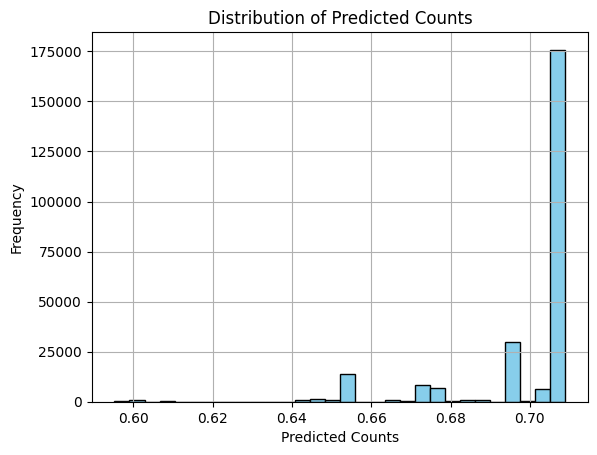

In [44]:
import matplotlib.pyplot as plt

# Flatten the predicted counts for all test images
flattened_predictions = test_predictions.flatten()

# Plot a histogram of the predicted counts
plt.hist(flattened_predictions, bins=30, color='skyblue', edgecolor='black')
plt.xlabel('Predicted Counts')
plt.ylabel('Frequency')
plt.title('Distribution of Predicted Counts')
plt.grid(True)
plt.show()


In [45]:
######################################

In [31]:
#Perform Inference: Use the loaded model to perform crowd counting on new images.
# Example of using the loaded model for inference
def perform_inference(model, image):
    # Preprocess the image (resize and normalize)
    resized_image = cv2.resize(image, (224, 224))
    normalized_image = resized_image / 255.0  # Assuming the original images are in the range [0, 255]

    # Perform inference
    crowd_density_map = model.predict(np.expand_dims(normalized_image, axis=0))

    # Calculate crowd count from the density map
    crowd_count = np.sum(crowd_density_map)

    return crowd_count

# Example usage
image = cv2.imread(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\test_data\images\IMG_15.jpg")  # Load an example image
crowd_count = perform_inference(loaded_model, image)
print("Estimated crowd count:", crowd_count)



1/1 [==============================] - 6s 6s/step
Estimated crowd count: 548.8782


1/1 [==============================] - 3s 3s/step


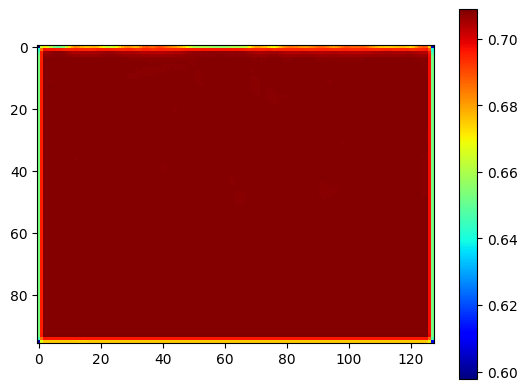

In [16]:
import matplotlib.pyplot as plt

# Example usage
image = cv2.imread(r"C:\Users\katel\OneDrive\Documents\OneDrive\Desktop\ShanghaiTechDataset\archive\ShanghaiTech\part_B\test_data\images\IMG_1.jpg")  # Load an example image
normalized_image = image / 255.0  # Normalize image

# Perform inference
crowd_density_map = loaded_model.predict(np.expand_dims(normalized_image, axis=0)).squeeze()

# Visualize crowd density map
plt.imshow(crowd_density_map, cmap='jet')
plt.colorbar()
plt.show()

In [49]:
# Define threshold (example)
threshold = 50

# Classify scenes
unsafe_scenes = []
safe_scenes = []

for i in range(len(test_images)):
    # Preprocess image
    normalized_image = test_images[i] / 255.0  # Assuming images are in range [0, 255]

    # Perform inference
    crowd_density_map = loaded_model.predict(np.expand_dims(normalized_image, axis=0)).squeeze()
    crowd_count = np.sum(crowd_density_map)

    # Classify scene
    if crowd_count > threshold:
        unsafe_scenes.append(i)  # Append the index of the unsafe scene
    else:
        safe_scenes.append(i)  # Append the index of the safe scene

# Print results
print("Number of unsafe scenes:", len(unsafe_scenes))
print("Number of safe scenes:", len(safe_scenes))


1/1 [==============================] - 0s 419ms/step
Number of unsafe scenes: 316
Number of safe scenes: 0
